In [1]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv("../data/raw/churn.csv")
assert df.shape == (7043, 21)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"]).drop(columns="customerID")

y = (df.pop("Churn") == "Yes").astype(int)
X = df

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

print(X.shape, y.mean().round(3))

(7032, 19) 0.266


### Data preparation
- Dropped the 11 new customers with no bill yet (see EDA).
- Dropped `customerID`: an identifier carries no information about behaviour
  and would let the model memorise individuals.
- `y` is the target (1 = left), and `X` holds the 19 features.

Result: 7,032 customers, with a 26.6% churn rate.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(len(X_train), len(X_test))

5625 1407


### Train/test split
The model learns from 5,625 customers. The remaining 1,407 are held back as a
final exam the model never sees during training.

- `stratify=y` keeps the 26.6% churn rate identical in both sets.
- `random_state=42` makes the split reproducible: same data, same results.

In [4]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42
    ),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    print(f"=== {name} ===  ROC-AUC: {roc_auc_score(y_test, proba):.3f}")
    print(classification_report(y_test, pipe.predict(X_test), digits=3))
    fitted[name] = pipe

=== Logistic Regression ===  ROC-AUC: 0.835
              precision    recall  f1-score   support

           0      0.905     0.700     0.789      1033
           1      0.490     0.797     0.607       374

    accuracy                          0.726      1407
   macro avg      0.698     0.748     0.698      1407
weighted avg      0.795     0.726     0.741      1407

=== Random Forest ===  ROC-AUC: 0.833
              precision    recall  f1-score   support

           0      0.903     0.736     0.811      1033
           1      0.517     0.781     0.622       374

    accuracy                          0.748      1407
   macro avg      0.710     0.758     0.716      1407
weighted avg      0.800     0.748     0.761      1407



### Model comparison

| Model | ROC-AUC | Recall (churn) | Precision (churn) |
|---|---|---|---|
| Logistic Regression | **0.835** | **0.80** | 0.49 |
| Random Forest | 0.833 | 0.78 | 0.52 |

**What the metrics mean:**
- **Recall 0.80:** of all customers who actually left, the model caught 80%.
- **Precision 0.49:** of the customers the model flagged, about half really left.
- **ROC-AUC 0.835:** pick one churner and one loyal customer at random, and the
  model rates the churner as riskier 83.5% of the time (0.5 = coin flip,
  1.0 = perfect).

**Why accuracy is not the headline:** a model predicting "nobody leaves" scores
73%, higher than ours, while being useless.

**The trade-off:** `class_weight="balanced"` makes the model sensitive, catching
most churners at the cost of false alarms. That suits churn, where a false alarm
costs a discount offer but a missed churner costs a whole customer.

**Choice:** the models are effectively tied, so **Logistic Regression** is kept
because its results can be explained.

confusion matrix (where the model gets it right and wrong)

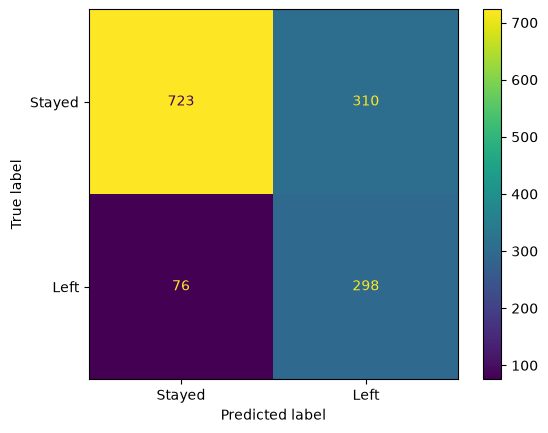

In [5]:
best = fitted["Logistic Regression"]
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["Stayed", "Left"])

### Confusion matrix
**How to read it:** rows are what actually happened, and columns are what the
model predicted.

| | Predicted: stayed | Predicted: left |
|---|---|---|
| **Actually stayed** | 723 correct | 310 false alarms |
| **Actually left** | 76 missed | **298 caught** |

**In practice:** contacting the 608 customers the model flags would reach 298 of
the 374 real churners. Without a model, the company would have to contact all
1,407 customers to reach the same people.

what drives churn, according to the model?

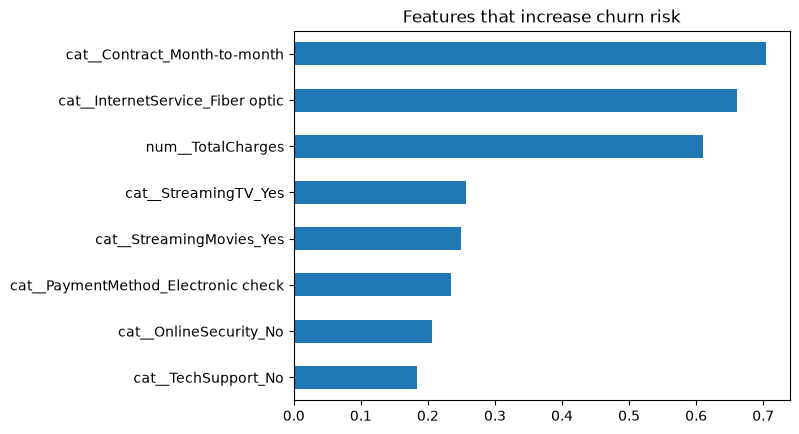

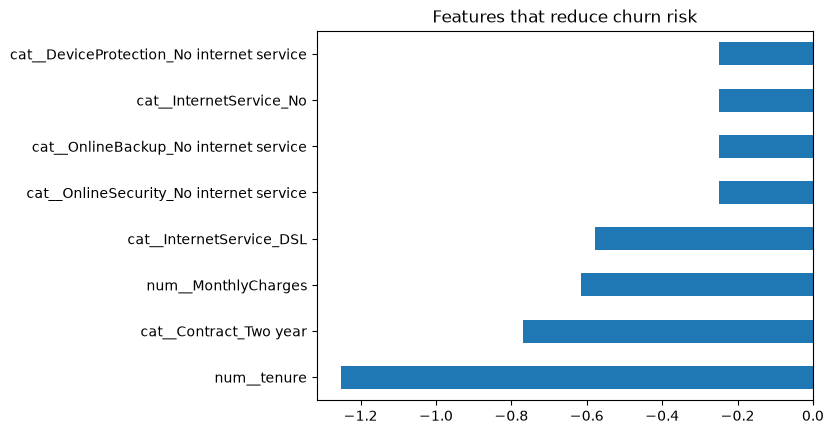

In [6]:
import matplotlib.pyplot as plt

names = best.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(best.named_steps["model"].coef_[0], index=names).sort_values()

coefs.tail(8).plot(kind="barh", title="Features that increase churn risk")
plt.show()
coefs.head(8).plot(kind="barh", title="Features that reduce churn risk")
plt.show()

### What drives churn according to the model?
**How to read it:** each bar is a logistic regression coefficient. Positive bars
(top chart) push the prediction toward "will leave", and negative bars (bottom
chart) push it toward "will stay". Longer bars have a stronger effect.

**Increases churn risk:**
- Month-to-month contract (strongest)
- Fibre-optic internet
- Electronic-check payment
- No online security, no tech support

**Reduces churn risk:**
- Long tenure (strongest overall)
- Two-year contract
- DSL internet

**Agreement with the EDA:** contract type and tenure dominate, as the charts
suggested.

**Caution: multicollinearity.** `MonthlyCharges` appears here as *reducing* risk,
the opposite of the EDA boxplot. This is not a real effect.
`TotalCharges` ≈ `tenure` × `MonthlyCharges`, so the three columns overlap and
the model splits the credit between them unpredictably. The price effect is also
partly absorbed by `Fibre optic`, the most expensive service. Coefficients
describe the model's internal bookkeeping, **not cause and effect**.

The four identical "No internet service" bars have the same cause: those columns
are always 1 together, so they share one effect.

In [7]:
joblib.dump(best, "../models/churn_model.joblib")

['../models/churn_model.joblib']